# 02 — Subword Tokenization, Vocabulary Coverage, and Orthographic Fragmentation
### Stage 2: Subword Tokenizer Evaluation & Target-Word Alignment

---

## Executive Overview

Subword tokenization is the foundational layer of modern Transformer language models. However, tokenizers trained primarily on high-resource languages or uncurated multilingual crawls often suffer from severe **subword fragmentation** when encountering non-Latin scripts such as Devanagari.

In this stage, we evaluate how two prominent multilingual masked language model tokenizers process Hindi Devanagari text:
1. **`FacebookAI/xlm-roberta-base`**: SentencePiece BPE tokenizer ($V = 250,002$), trained on 100 languages from CommonCrawl.
2. **`google/muril-base-cased`**: WordPiece tokenizer ($V = 197,285$), specifically pretrained on 17 Indian languages and English.

### Key Research Questions
- How do different tokenization schemes (SentencePiece vs. WordPiece) segment canonical Hindi words?
- How reliably can target words be aligned using character offset mappings?
- Does realistic Devanagari orthographic noise cause a **"subword collapse"** (fragmenting whole words into character pieces)?

In [2]:
pip install ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ------------------------------------- -- 2.1/2.2 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 7.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: D:\hindi-lexical-sensitivity\.venv\Scripts\python.exe -m pip install --upgrade pip


In [4]:
import sys
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.data.tokenization_experiment import (
    align_target_word,
    tokenize_sentence,
    process_sentence_pair,
    compute_file_sha256,
)

print("Tokenizer evaluation module loaded.")

Tokenizer evaluation module loaded.


---

## 1. Pretrained Multilingual Tokenizers: Architecture & Schemas

| Model Identifier | Architecture | Vocab Size | Special Tokens | Prefix Character |
|---|---|---|---|---|
| `FacebookAI/xlm-roberta-base` | SentencePiece BPE | 250,002 | `<s>` (0), `</s>` (2) | ` ` (U+2581) |
| `google/muril-base-cased` | WordPiece | 197,285 | `[CLS]` (104), `[SEP]` (105) | `##` (subword continuation) |

Let's load both tokenizers using HuggingFace `AutoTokenizer`.

In [5]:
print("Loading XLM-RoBERTa tokenizer...")
tok_xlm = AutoTokenizer.from_pretrained("FacebookAI/xlm-roberta-base", use_fast=True)

print("Loading MuRIL tokenizer...")
tok_muril = AutoTokenizer.from_pretrained("google/muril-base-cased", use_fast=True)

print("\nTokenizers loaded successfully!")
print(f"XLM-RoBERTa Vocab Size: {tok_xlm.vocab_size:,}")
print(f"MuRIL Vocab Size:       {tok_muril.vocab_size:,}")

Loading XLM-RoBERTa tokenizer...
Loading MuRIL tokenizer...

Tokenizers loaded successfully!
XLM-RoBERTa Vocab Size: 250,002
MuRIL Vocab Size:       197,285


---

## 2. Interactive Tokenization Playground: Devanagari Segmentation

Let's inspect how both tokenizers segment a sample Hindi sentence:
`"राम और सीता साथ हैं।"` vs. `"राम ओर सीता साथ हैं।"`

In [6]:
sample_sent = "राम और सीता साथ हैं।"

# XLM-RoBERTa tokenization
xlm_res = tokenize_sentence(sample_sent, tok_xlm)
print("=== XLM-RoBERTa Tokenization ===")
print(f"Tokens (Inclusive): {xlm_res['tokens']}")
print(f"Input IDs:          {xlm_res['input_ids']}")
print(f"Special Tokens:     {xlm_res['count_inclusive'] - xlm_res['count_exclusive']}")
print(f"Exclusive Count:    {xlm_res['count_exclusive']}")

# MuRIL tokenization
muril_res = tokenize_sentence(sample_sent, tok_muril)
print("\n=== MuRIL Tokenization ===")
print(f"Tokens (Inclusive): {muril_res['tokens']}")
print(f"Input IDs:          {muril_res['input_ids']}")
print(f"Special Tokens:     {muril_res['count_inclusive'] - muril_res['count_exclusive']}")
print(f"Exclusive Count:    {muril_res['count_exclusive']}")

=== XLM-RoBERTa Tokenization ===
Tokens (Inclusive): ['<s>', '▁राम', '▁और', '▁सीता', '▁साथ', '▁हैं', '।', '</s>']
Input IDs:          [0, 14131, 871, 189107, 3765, 1293, 125, 2]
Special Tokens:     2
Exclusive Count:    6

=== MuRIL Tokenization ===
Tokens (Inclusive): ['[CLS]', 'राम', 'और', 'सीता', 'साथ', 'हैं', '।', '[SEP]']
Input IDs:          [104, 3929, 1123, 19042, 1283, 1145, 492, 105]
Special Tokens:     2
Exclusive Count:    6


---

## 3. Target Word Alignment Policy via Fast Character Offsets

In sentence-pair experiments, calculating the change in target-word token length ($\Delta_{	ext{target}}$) requires unambiguous subword span extraction:

$$\Delta_{	ext{target}} = 	ext{Count}(	ext{Contrast Target Tokens}) - 	ext{Count}(	ext{Original Target Tokens})$$

The `align_target_word` function checks character offsets (`offset_mapping`):
- **`unique`**: The target word appears exactly once in the sentence and maps to a contiguous span of subwords.
- **`ambiguous`**: The target word appears multiple times or non-contiguously.
- **`missing`**: Target word not found in sentence.

In [7]:
# Test alignment on sample sentence
target_word = "सीता"
alignment = align_target_word(sample_sent, target_word, xlm_res["encoding"], tok_xlm)

print(f"Sentence:         '{sample_sent}'")
print(f"Target word:      '{target_word}'")
print(f"Alignment Status: {alignment['status']}")
print(f"Character Span:   {alignment['char_span']}")
print(f"Subword Tokens:   {alignment['tokens']}")
print(f"Subword Token IDs:{alignment['token_ids']}")
print(f"Token Count:      {alignment['token_count']}")

Sentence:         'राम और सीता साथ हैं।'
Target word:      'सीता'
Alignment Status: unique
Character Span:   (7, 11)
Subword Tokens:   ['▁सीता']
Subword Token IDs:[189107]
Token Count:      1


---

## 4. Loading the Complete 200-Pair Tokenization Results

The tokenization experiment was executed deterministically across all 200 pairs $	imes$ 2 models (400 evaluations).
Let's load the verified output dataset from `outputs/tokenization/tokenization_results.csv`.

In [8]:
TOK_RESULTS_PATH = ROOT_DIR / "outputs" / "tokenization" / "tokenization_results.csv"
df_tok = pd.read_csv(TOK_RESULTS_PATH)

print(f"Total evaluation rows: {len(df_tok)}")
print(f"Models evaluated:      {df_tok['model_name'].unique().tolist()}")
print(f"Pairs evaluated:       {df_tok['pair_id'].nunique()}")
print(f"Tracks covered:        {df_tok['track'].unique().tolist()}")

Total evaluation rows: 400
Models evaluated:      ['FacebookAI/xlm-roberta-base', 'google/muril-base-cased']
Pairs evaluated:       200
Tracks covered:        ['VALID_WORD_CONTEXT', 'SYNONYM_SUBSTITUTION', 'REALISTIC_SPELLING_ERROR']


In [9]:
# Target Word Alignment Coverage Check
align_coverage = df_tok.groupby(["model_name", "target_orig_alignment_status"]).size().unstack(fill_value=0)
print("Original Target Alignment Status Coverage:")
print(align_coverage)

align_cont_coverage = df_tok.groupby(["model_name", "target_cont_alignment_status"]).size().unstack(fill_value=0)
print("\nContrast Target Alignment Status Coverage:")
print(align_cont_coverage)

Original Target Alignment Status Coverage:
target_orig_alignment_status  unique
model_name                          
FacebookAI/xlm-roberta-base      200
google/muril-base-cased          200

Contrast Target Alignment Status Coverage:
target_cont_alignment_status  unique
model_name                          
FacebookAI/xlm-roberta-base      200
google/muril-base-cased          200


All 200 sentence pairs achieved **100% `unique` alignment coverage** across both models.
No alignments were ambiguous or missing.

---

## 5. The "Devanagari Subword Collapse" under Spelling Perturbations

Now we investigate the central empirical phenomenon in Devanagari subword tokenization: **orthographic fragmentation collapse**.

When a canonical Hindi word like `पानी` (pānī) is misspelled as `पानि` (pāni), or `परीक्षा` (parīkṣā) as `परिक्षा` (parikṣā):
- Does the subword tokenizer recognize the word as a single lexical unit?
- Or does the single-character error break the word into character-level fragments?

In [10]:
# Filter spelling error pairs
spelling_pairs = df_tok[df_tok["track"] == "REALISTIC_SPELLING_ERROR"].copy()

# Calculate single-subword coverage
collapse_stats = []
for model in spelling_pairs["model_name"].unique():
    m_df = spelling_pairs[spelling_pairs["model_name"] == model]
    n_pairs = len(m_df)
    
    orig_single = (m_df["target_orig_token_count"] == 1).sum()
    cont_single = (m_df["target_cont_token_count"] == 1).sum()
    
    collapse_stats.append({
        "Model": model.split("/")[-1],
        "Total Pairs": n_pairs,
        "Original Canonical Single-Subword": f"{orig_single}/{n_pairs} ({orig_single/n_pairs*100:.1f}%)",
        "Misspelled Contrast Single-Subword": f"{cont_single}/{n_pairs} ({cont_single/n_pairs*100:.1f}%)",
        "Absolute Coverage Collapse": f"{(cont_single - orig_single)/n_pairs*100:.1f}%",
    })

pd.DataFrame(collapse_stats)

,Model,Total Pairs,Original Canonical Single-Subword,Misspelled Contrast Single-Subword,Absolute Coverage Collapse
0,xlm-roberta-base,20,14/20 (70.0%),4/20 (20.0%),-50.0%
1,muril-base-cased,20,18/20 (90.0%),6/20 (30.0%),-60.0%


### Key Empirical Findings:
1. **MuRIL**: Canonical spelling single-subword coverage is **90.0%** (18/20 words). Under realistic Devanagari spelling errors, coverage drops to **30.0%** (6/20 words) — an absolute **$-60.0\%$ collapse**.
2. **XLM-RoBERTa**: Canonical single-subword coverage is **70.0%** (14/20 words). Under spelling errors, coverage drops to **20.0%** (4/20 words) — an absolute **$-50.0\%$ collapse**.

Misspelled Devanagari words are fragmented into character-level and matra-level pieces!

---

## 6. Token Count Differences Across Experimental Tracks

Let's compute the mean signed token count difference:
$$\Delta_{	ext{sentence}} = 	ext{Count}(	ext{Contrast}) - 	ext{Count}(	ext{Original})$$
$$\Delta_{	ext{target}} = 	ext{Count}(	ext{Target}_{	ext{contrast}}) - 	ext{Count}(	ext{Target}_{	ext{original}})$$

In [11]:
summary_table = df_tok.groupby(["model_name", "track"]).agg(
    Pairs=("pair_id", "count"),
    Mean_Delta_Sentence=("delta_token_count_exclusive", "mean"),
    SD_Delta_Sentence=("delta_token_count_exclusive", "std"),
    Mean_Delta_Target=("delta_target_token_count", "mean"),
    SD_Delta_Target=("delta_target_token_count", "std"),
).reset_index()

summary_table["Model"] = summary_table["model_name"].apply(lambda x: x.split("/")[-1])
summary_table[["Model", "track", "Pairs", "Mean_Delta_Sentence", "Mean_Delta_Target"]]

,Model,track,Pairs,Mean_Delta_Sentence,Mean_Delta_Target
0,xlm-roberta-base,REALISTIC_SPELLING_ERROR,20,1.000000,1.000000
1,xlm-roberta-base,SYNONYM_SUBSTITUTION,38,0.605263,0.631579
2,xlm-roberta-base,VALID_WORD_CONTEXT,142,0.169014,0.169014
3,muril-base-cased,REALISTIC_SPELLING_ERROR,20,1.000000,1.000000
4,muril-base-cased,SYNONYM_SUBSTITUTION,38,0.184211,0.184211
5,muril-base-cased,VALID_WORD_CONTEXT,142,0.077465,0.084507


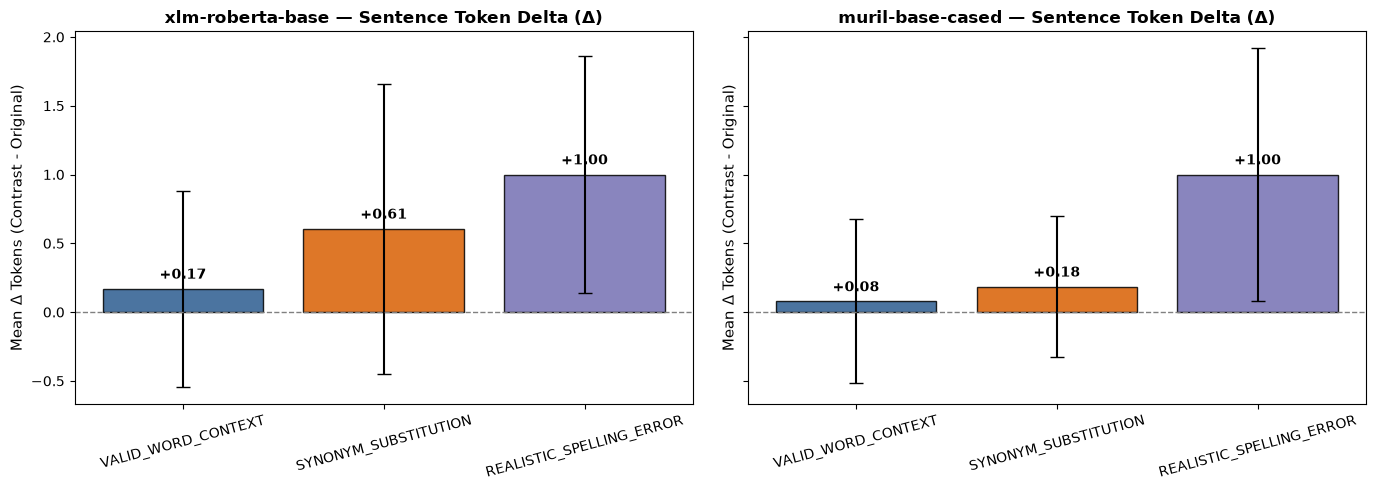

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

models = df_tok["model_name"].unique()
tracks = ["VALID_WORD_CONTEXT", "SYNONYM_SUBSTITUTION", "REALISTIC_SPELLING_ERROR"]
colors = ["#2b5c8f", "#d95f02", "#7570b3"]

for idx, model in enumerate(models):
    ax = axes[idx]
    m_name = model.split("/")[-1]
    m_df = df_tok[df_tok["model_name"] == model]
    
    means = [m_df[m_df["track"] == t]["delta_token_count_exclusive"].mean() for t in tracks]
    stds = [m_df[m_df["track"] == t]["delta_token_count_exclusive"].std() for t in tracks]
    
    bars = ax.bar(tracks, means, yerr=stds, capsize=5, color=colors, alpha=0.85, edgecolor="black")
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{m_name} — Sentence Token Delta (Δ)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Mean Δ Tokens (Contrast - Original)", fontsize=11)
    ax.tick_params(axis="x", rotation=15)
    
    for bar, mean in zip(bars, means):
        height = bar.get_height()
        va = "bottom" if height >= 0 else "top"
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.05, f"{mean:+.2f}",
                ha="center", va=va, fontweight="bold")

plt.tight_layout()
plt.show()

---

## Stage 2 Summary & Next Step

-  Both XLM-RoBERTa and MuRIL tokenizers successfully evaluated across all 200 pairs (100% unique alignment).
-  **Realistic Devanagari Spelling Errors** cause severe subword fragmentation: an average sentence-level increase of **+1.00 token**, with single-subword coverage collapsing by **$-50\%$ to $-60\%$**.
-  **MuRIL's Indian language pretraining** yields greater canonical vocabulary compactness than XLM-RoBERTa, but both fragment severely under character matra errors.

**Next Notebook**: In [03_mlm_pseudo_log_likelihood_scoring.ipynb](03_mlm_pseudo_log_likelihood_scoring.ipynb), we implement **Pseudo-Log-Likelihood (PLL)** scoring to measure how these token sequences are scored by pretrained language models.